# Homework 4 — Imbalanced Learning
## Porto Seguro's Safe Driver Prediction (Kaggle)

**Goal.** Predict the probability that an auto-insurance policy holder files a claim
in the next year. The target is highly imbalanced (~3.6% positives).

**Scoring metric.** Normalized Gini Coefficient, equivalent to `2 * AUC - 1`.

**Pipeline implemented in this notebook**
1. Exploratory analysis — class imbalance, missingness, per-feature target distribution, correlations.
2. Feature engineering — `num_missing`, `mix_ind`, count encoding, one-hot encoding of categoricals, sparse-matrix assembly, and a justified feature-removal step.
3. Modelling — LightGBM with Stratified K-Fold cross-validation, a custom Gini evaluation metric, Bayesian hyper-parameter optimization, and early stopping.
4. Prediction — fold-averaged test probabilities written to `submission.csv` in the Kaggle format.

## 1. Setup

In [1]:
import os
import warnings

import numpy as np
import pandas as pd
from scipy import sparse
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import StratifiedKFold
import lightgbm as lgb
from bayes_opt import BayesianOptimization
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 110

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
print("LightGBM", lgb.__version__)

LightGBM 4.6.0


In [2]:
# ----------------------------- Configuration -----------------------------
DATA_DIR = "/Users/emecheverria/Downloads/porto-seguro-safe-driver-prediction"
OUT_DIR = "."

# SAMPLE_FRAC < 1.0 runs a fast smoke test on a stratified subsample.
# Set to 1.0 for the full, submission-quality run.
SAMPLE_FRAC = 1.0

N_FOLDS = 5                 # Stratified K-Fold splits

# Bayesian optimization budget (total evaluations = init + iter).
BO_INIT_POINTS = 4
BO_N_ITER = 8
BO_FOLDS = 3               # cheaper CV used only inside the search
BO_LR = 0.05               # higher LR + early stopping keeps the search fast
BO_MAX_ROUNDS = 1500
BO_EARLY_STOP = 50

# Final model: low learning rate + many rounds, as recommended for convergence.
FINAL_LR = 0.01
FINAL_MAX_ROUNDS = 8000
FINAL_EARLY_STOP = 200

# scale_pos_weight handles imbalance in the gradient. It mainly affects score
# *calibration*, not ranking (Gini is rank-based), so it is optional here.
USE_SCALE_POS_WEIGHT = False

## 2. Scoring metric — Normalized Gini

The exact implementation from the assignment brief. `eval_gini` returns the
normalized Gini coefficient; `gini_lgb` wraps it as a LightGBM custom metric
(`is_higher_better=True`).

In [3]:
def eval_gini(y_true, y_pred):
    '''Normalized Gini coefficient (assignment reference implementation).'''
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    assert y_true.shape == y_pred.shape
    n_samples = y_true.shape[0]
    L_mid = np.linspace(1 / n_samples, 1, n_samples)

    # Gini for the predicted ordering
    pred_order = y_true[y_pred.argsort()]
    L_pred = np.cumsum(pred_order) / np.sum(pred_order)
    G_pred = np.sum(L_mid - L_pred)

    # Gini for a perfect ordering
    true_order = y_true[y_true.argsort()]
    L_true = np.cumsum(true_order) / np.sum(true_order)
    G_true = np.sum(L_mid - L_true)

    return G_pred / G_true


def gini_lgb(y_pred, dataset):
    '''LightGBM feval wrapper: returns (name, value, is_higher_better).'''
    y_true = dataset.get_label()
    return "gini", eval_gini(y_true, y_pred), True

## 3. Load data

In [4]:
train = pd.read_csv(os.path.join(DATA_DIR, "train.csv"))
test = pd.read_csv(os.path.join(DATA_DIR, "test.csv"))

if SAMPLE_FRAC < 1.0:
    from sklearn.model_selection import train_test_split
    _, train = train_test_split(
        train, test_size=SAMPLE_FRAC,
        stratify=train["target"], random_state=RANDOM_STATE)
    train = train.reset_index(drop=True)
    print(f"Sub-sampled train to {len(train):,} rows (SAMPLE_FRAC={SAMPLE_FRAC}).")

print("train:", train.shape, "| test:", test.shape)
train.head()

train: (595212, 59) | test: (892816, 58)


,id,target,ps_ind_01,ps_ind_02_cat,ps_ind_03,ps_ind_04_cat,ps_ind_05_cat,ps_ind_06_bin,ps_ind_07_bin,ps_ind_08_bin,...,ps_calc_11,ps_calc_12,ps_calc_13,ps_calc_14,ps_calc_15_bin,ps_calc_16_bin,ps_calc_17_bin,ps_calc_18_bin,ps_calc_19_bin,ps_calc_20_bin
0,7,0,2,2,5,1,0,0,1,0,...,9,1,5,8,0,1,1,0,0,1
1,9,0,1,1,7,0,0,0,0,1,...,3,1,1,9,0,1,1,0,1,0
2,13,0,5,4,9,1,0,0,0,1,...,4,2,7,7,0,1,1,0,1,0
3,16,0,0,1,2,0,0,1,0,0,...,2,2,4,9,0,0,0,0,0,0
4,17,0,0,2,0,1,0,1,0,0,...,3,1,1,3,0,0,0,1,1,0


In [5]:
feature_cols = [c for c in train.columns if c not in ("id", "target")]
bin_features = [c for c in feature_cols if c.endswith("_bin")]
cat_features = [c for c in feature_cols if c.endswith("_cat")]
num_features = [c for c in feature_cols if c not in bin_features + cat_features]
ind_features = [c for c in feature_cols if c.startswith("ps_ind")]
calc_features = [c for c in feature_cols if c.startswith("ps_calc")]

print(f"{len(feature_cols)} features: "
      f"{len(bin_features)} binary, {len(cat_features)} categorical, "
      f"{len(num_features)} continuous/ordinal")
print(f"{len(calc_features)} are ps_calc_* features")

57 features: 17 binary, 14 categorical, 26 continuous/ordinal
20 are ps_calc_* features


## 4. Exploratory analysis

### 4.1 Class imbalance

Positives: 21,694 (3.64%) | Negatives: 573,518
Negative/positive ratio (scale_pos_weight): 26.44


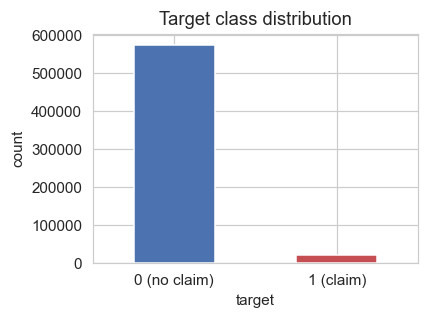

In [6]:
pos_rate = train["target"].mean()
n_pos = int(train["target"].sum())
n_neg = len(train) - n_pos
scale_pos_weight = n_neg / n_pos
print(f"Positives: {n_pos:,} ({pos_rate:.2%}) | Negatives: {n_neg:,}")
print(f"Negative/positive ratio (scale_pos_weight): {scale_pos_weight:.2f}")

ax = train["target"].value_counts().sort_index().plot(
    kind="bar", color=["#4C72B0", "#C44E52"], figsize=(4, 3))
ax.set_xticklabels(["0 (no claim)", "1 (claim)"], rotation=0)
ax.set_title("Target class distribution")
ax.set_ylabel("count")
plt.tight_layout(); plt.show()

### 4.2 Missing values (`-1` sentinel)

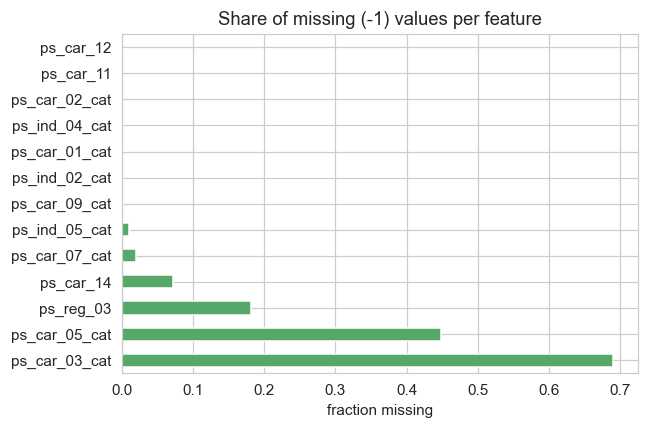

,missing_fraction
ps_car_03_cat,69.09%
ps_car_05_cat,44.78%
ps_reg_03,18.11%
ps_car_14,7.16%
ps_car_07_cat,1.93%
ps_ind_05_cat,0.98%
ps_car_09_cat,0.10%
ps_ind_02_cat,0.04%
ps_car_01_cat,0.02%
ps_ind_04_cat,0.01%


In [7]:
missing_share = (train[feature_cols] == -1).mean()
missing_share = missing_share[missing_share > 0].sort_values(ascending=False)

ax = missing_share.plot(kind="barh", figsize=(6, 4), color="#55A868")
ax.set_title("Share of missing (-1) values per feature")
ax.set_xlabel("fraction missing")
plt.tight_layout(); plt.show()
missing_share.to_frame("missing_fraction").style.format("{:.2%}")

A handful of features carry most of the missingness (`ps_car_03_cat` ~69%,
`ps_car_05_cat` ~45%, `ps_reg_03` ~18%). The **pattern** of missingness can
itself be predictive, motivating the `num_missing` feature below.

### 4.3 Per-feature target distribution

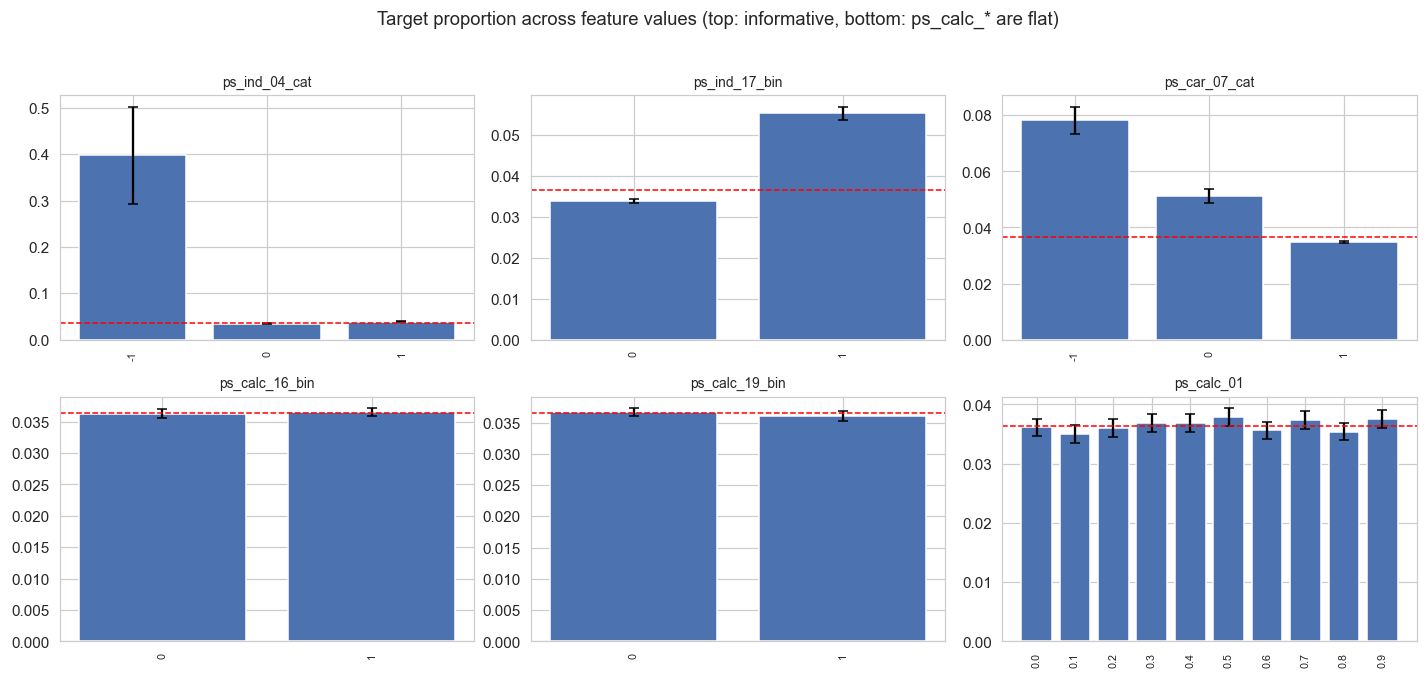

In [8]:
def plot_target_proportion(cols, axes):
    '''Bar of P(target=1 | feature value) with 95% CI; flat bars => low signal.'''
    for col, ax in zip(cols, axes):
        grp = train.groupby(col)["target"].agg(["mean", "count"])
        se = np.sqrt(grp["mean"] * (1 - grp["mean"]) / grp["count"])
        ax.bar(grp.index.astype(str), grp["mean"], yerr=1.96 * se,
               color="#4C72B0", capsize=3)
        ax.axhline(pos_rate, color="red", ls="--", lw=1, label="base rate")
        ax.set_title(col, fontsize=9)
        ax.tick_params(axis="x", labelrotation=90, labelsize=7)

examples = ["ps_ind_04_cat", "ps_ind_17_bin", "ps_car_07_cat",
            "ps_calc_16_bin", "ps_calc_19_bin", "ps_calc_01"]
fig, axes = plt.subplots(2, 3, figsize=(13, 6))
plot_target_proportion(examples, axes.ravel())
fig.suptitle("Target proportion across feature values "
             "(top: informative, bottom: ps_calc_* are flat)", y=1.02)
plt.tight_layout(); plt.show()

In [9]:
# Quantify signal: spread = max - min of P(target=1|value) for low-cardinality features.
spreads = {}
for col in feature_cols:
    if train[col].nunique() <= 12:
        g = train.groupby(col)["target"].mean()
        spreads[col] = g.max() - g.min()
spread_s = pd.Series(spreads).sort_values()
print("Lowest-signal features (smallest target-proportion spread):")
print(spread_s.head(12).to_string())

Lowest-signal features (smallest target-proportion spread):
ps_calc_17_bin    0.000064
ps_calc_18_bin    0.000229
ps_calc_16_bin    0.000242
ps_calc_15_bin    0.000280
ps_calc_20_bin    0.000558
ps_calc_19_bin    0.000686
ps_calc_04        0.002361
ps_ind_18_bin     0.002369
ps_calc_03        0.002442
ps_calc_02        0.002722
ps_calc_09        0.002831
ps_calc_01        0.002839


The `ps_calc_*` binary features show essentially no variation in target
proportion (spread < 0.001) — they are noise. This is consistent with the
assignment's guidance to drop the `calc` block.

### 4.4 Correlation among continuous features

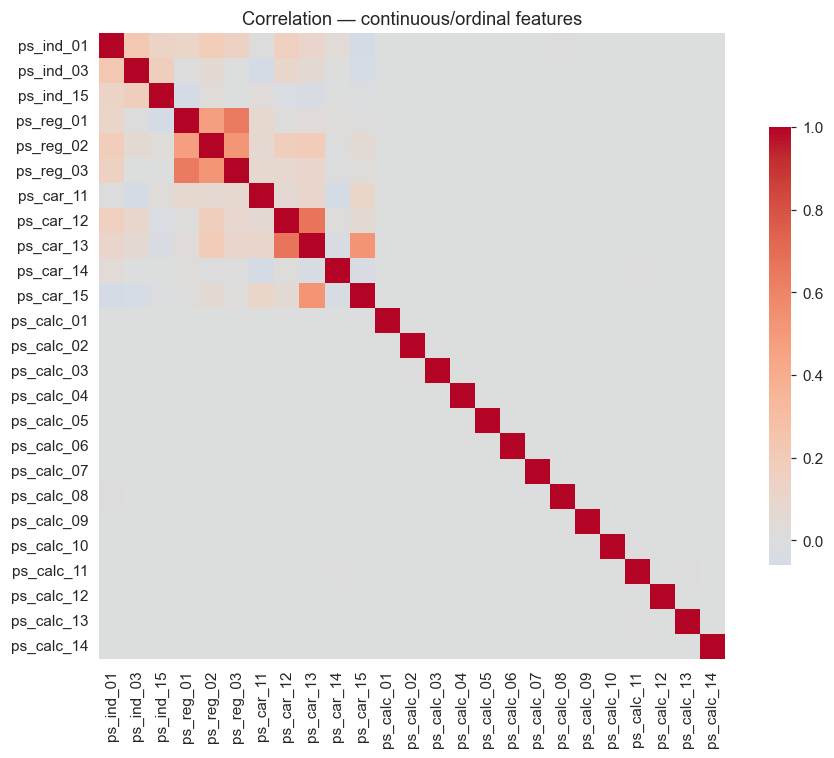

Pairs with |corr| > 0.5:
ps_car_13  ps_car_12    0.671720
ps_reg_01  ps_reg_03    0.637035
ps_car_13  ps_car_15    0.529519
ps_reg_03  ps_reg_02    0.516457


In [10]:
cont = [c for c in num_features if c not in ("ps_ind_14",)]
corr = train[cont].corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr, cmap="coolwarm", center=0, square=True,
            cbar_kws={"shrink": 0.7})
plt.title("Correlation — continuous/ordinal features")
plt.tight_layout(); plt.show()

high = (corr.abs().where(~np.eye(len(corr), dtype=bool))
        .stack().sort_values(ascending=False))
high = high[high > 0.5].drop_duplicates()
print("Pairs with |corr| > 0.5:")
print(high.to_string())

## 5. Feature engineering

Implemented per the assignment hints:

| Step | What |
|------|------|
| `num_missing` | per-row count of `-1` sentinels |
| `mix_ind` | underscore-concatenation of all `ps_ind_*` features (interaction string) |
| count encoding | frequency of each value for every categorical + `mix_ind` (`*_count`) |
| one-hot | `OneHotEncoder` on `*_cat` features → sparse |
| removal | drop `ps_calc_*`, rare `ps_ind_1x_bin`, `ps_ind_14`, `ps_car_14` |
| assembly | `scipy.sparse.hstack` of numeric block + one-hot block |

In [11]:
# Features to remove (justified by EDA above and the assignment brief):
#   - all ps_calc_*            : no discriminative power (flat target proportion)
#   - ps_ind_10..13_bin        : extremely rare, statistically unreliable (wide CIs)
#   - ps_ind_14                : low signal / noisy
#   - ps_car_14                : redundant / correlated, heavy missingness
DROP_FEATURES = (
    calc_features
    + ["ps_ind_10_bin", "ps_ind_11_bin", "ps_ind_12_bin", "ps_ind_13_bin"]
    + ["ps_ind_14", "ps_car_14"]
)
print(f"Dropping {len(DROP_FEATURES)} features.")

Dropping 26 features.


In [12]:
def engineer_features(train_df, test_df):
    '''Build sparse train/test design matrices.

    Train and test are processed together so that count encodings, one-hot
    categories, and the mix_ind vocabulary are consistent across both.
    '''
    n_train = len(train_df)
    df = pd.concat([train_df.drop(columns=["target"]), test_df],
                   axis=0, ignore_index=True)

    # (1) num_missing — computed over the ORIGINAL feature set, before removal.
    df["num_missing"] = (df[feature_cols] == -1).sum(axis=1)

    # (2) mix_ind — interaction string over all indicator features.
    df["mix_ind"] = df[ind_features].astype(str).agg("_".join, axis=1)

    # (3) Count encoding for every categorical feature plus mix_ind.
    count_cols = []
    for col in cat_features + ["mix_ind"]:
        counts = df[col].value_counts()
        df[col + "_count"] = df[col].map(counts).astype(np.float32)
        count_cols.append(col + "_count")

    # (4) Numeric block: kept continuous/ordinal + binary + engineered counts
    #     + num_missing. (Categoricals go through one-hot instead.)
    keep_num = [c for c in num_features + bin_features if c not in DROP_FEATURES]
    numeric_cols = keep_num + count_cols + ["num_missing"]
    X_numeric = sparse.csr_matrix(df[numeric_cols].astype(np.float32).values)

    # (5) One-hot encoding of categorical features (sparse).
    ohe = OneHotEncoder(handle_unknown="ignore", dtype=np.float32)
    X_cat = ohe.fit_transform(df[cat_features])

    # (6) Assemble.
    X_all = sparse.hstack([X_numeric, X_cat], format="csr")
    feature_names = (numeric_cols
                     + list(ohe.get_feature_names_out(cat_features)))

    X_tr = X_all[:n_train]
    X_te = X_all[n_train:]
    return X_tr, X_te, feature_names


X, X_test, feat_names = engineer_features(train, test)
y = train["target"].values
test_ids = test["id"].values

density = X.nnz / (X.shape[0] * X.shape[1])
print(f"X (train): {X.shape} | X_test: {X_test.shape}")
print(f"Total engineered columns: {len(feat_names)} | density: {density:.3f}")

X (train): (595212, 217) | X_test: (892816, 217)
Total engineered columns: 217 | density: 0.189


## 6. Modelling — LightGBM

Strategy: Stratified K-Fold CV (preserves the 3.6% positive rate per fold),
custom Gini metric, early stopping on the validation fold, and Bayesian
optimization over the hyper-parameter ranges suggested in the brief.

In [13]:
BASE_PARAMS = {
    "objective": "binary",
    "boosting_type": "gbdt",
    "metric": "None",          # we drive early stopping with the custom Gini feval
    "verbosity": -1,
    "seed": RANDOM_STATE,
    "feature_pre_filter": False,
}
if USE_SCALE_POS_WEIGHT:
    BASE_PARAMS["scale_pos_weight"] = scale_pos_weight


def cv_gini(params, n_folds, learning_rate, max_rounds, early_stop, seed=RANDOM_STATE):
    '''Out-of-fold normalized Gini for a parameter set.'''
    skf = StratifiedKFold(n_splits=n_folds, shuffle=True, random_state=seed)
    oof = np.zeros(len(y))
    p = {**BASE_PARAMS, **params, "learning_rate": learning_rate}
    for tr_idx, va_idx in skf.split(X, y):
        dtr = lgb.Dataset(X[tr_idx], y[tr_idx])
        dva = lgb.Dataset(X[va_idx], y[va_idx], reference=dtr)
        model = lgb.train(
            p, dtr, num_boost_round=max_rounds,
            valid_sets=[dva], feval=gini_lgb,
            callbacks=[lgb.early_stopping(early_stop, verbose=False)],
        )
        oof[va_idx] = model.predict(X[va_idx], num_iteration=model.best_iteration)
    return eval_gini(y, oof)

### 6.1 Bayesian hyper-parameter optimization

In [14]:
PBOUNDS = {
    "num_leaves": (30, 40),
    "lambda_l1": (0.7, 0.9),
    "lambda_l2": (0.9, 1.0),
    "feature_fraction": (0.6, 0.7),
    "bagging_fraction": (0.6, 0.9),
    "min_child_samples": (6, 10),
    "min_child_weight": (10, 40),
}


def lgb_objective(num_leaves, lambda_l1, lambda_l2, feature_fraction,
                  bagging_fraction, min_child_samples, min_child_weight):
    params = {
        "num_leaves": int(round(num_leaves)),
        "lambda_l1": lambda_l1,
        "lambda_l2": lambda_l2,
        "feature_fraction": feature_fraction,
        "bagging_fraction": bagging_fraction,
        "bagging_freq": 1,
        "min_child_samples": int(round(min_child_samples)),
        "min_child_weight": min_child_weight,
    }
    return cv_gini(params, BO_FOLDS, BO_LR, BO_MAX_ROUNDS, BO_EARLY_STOP)


optimizer = BayesianOptimization(
    f=lgb_objective, pbounds=PBOUNDS, random_state=RANDOM_STATE, verbose=2)
optimizer.maximize(init_points=BO_INIT_POINTS, n_iter=BO_N_ITER)
print("\nBest CV Gini:", round(optimizer.max["target"], 5))
print("Best params:", optimizer.max["params"])

|   iter    |  target   | num_le... | lambda_l1 | lambda_l2 | featur... | baggin... | min_ch... | min_ch... |
-------------------------------------------------------------------------------------------------------------
| 1         | 0.2843920 | 33.745401 | 0.8901428 | 0.9731993 | 0.6598658 | 0.6468055 | 6.6239780 | 11.742508 |
| 2         | 0.2841232 | 38.661761 | 0.8202230 | 0.9708072 | 0.6020584 | 0.8909729 | 9.3297705 | 16.370173 |
| 3         | 0.2847061 | 31.818249 | 0.7366809 | 0.9304242 | 0.6524756 | 0.7295835 | 7.1649165 | 28.355586 |
| 4         | 0.2849254 | 31.394938 | 0.7584289 | 0.9366361 | 0.6456069 | 0.8355527 | 6.7986951 | 25.427033 |
| 5         | 0.2851426 | 30.006533 | 0.7994490 | 0.9702746 | 0.6040707 | 0.8607759 | 9.8974762 | 22.775795 |
| 6         | 0.2853182 | 30.0      | 0.9       | 1.0       | 0.7       | 0.6956821 | 6.0       | 19.994514 |
| 7         | 0.2843322 | 39.944777 | 0.7955350 | 0.9343473 | 0.6950276 | 0.7391600 | 7.9104016 | 39.884049 |
| 8       

In [15]:
best = optimizer.max["params"]
best_params = {
    "num_leaves": int(round(best["num_leaves"])),
    "lambda_l1": best["lambda_l1"],
    "lambda_l2": best["lambda_l2"],
    "feature_fraction": best["feature_fraction"],
    "bagging_fraction": best["bagging_fraction"],
    "bagging_freq": 1,
    "min_child_samples": int(round(best["min_child_samples"])),
    "min_child_weight": best["min_child_weight"],
}
final_params = {**BASE_PARAMS, **best_params, "learning_rate": FINAL_LR}
final_params

{'objective': 'binary',
 'boosting_type': 'gbdt',
 'metric': 'None',
 'verbosity': -1,
 'seed': 42,
 'feature_pre_filter': False,
 'num_leaves': 30,
 'lambda_l1': np.float64(0.9),
 'lambda_l2': np.float64(1.0),
 'feature_fraction': np.float64(0.7),
 'bagging_fraction': np.float64(0.6956821007117984),
 'bagging_freq': 1,
 'min_child_samples': 6,
 'min_child_weight': np.float64(19.99451477984379),
 'learning_rate': 0.01}

### 6.2 Final training with fold-averaged test predictions

In [16]:
skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)
oof_pred = np.zeros(len(y))
test_pred = np.zeros(X_test.shape[0])
fold_gini = []

for fold, (tr_idx, va_idx) in enumerate(skf.split(X, y), 1):
    dtr = lgb.Dataset(X[tr_idx], y[tr_idx])
    dva = lgb.Dataset(X[va_idx], y[va_idx], reference=dtr)
    model = lgb.train(
        final_params, dtr, num_boost_round=FINAL_MAX_ROUNDS,
        valid_sets=[dtr, dva], valid_names=["train", "valid"],
        feval=gini_lgb,
        callbacks=[
            lgb.early_stopping(FINAL_EARLY_STOP, verbose=False),
            lgb.log_evaluation(500),
        ],
    )
    oof_pred[va_idx] = model.predict(X[va_idx], num_iteration=model.best_iteration)
    test_pred += model.predict(X_test, num_iteration=model.best_iteration) / N_FOLDS
    g = eval_gini(y[va_idx], oof_pred[va_idx])
    fold_gini.append(g)
    print(f"Fold {fold}: best_iter={model.best_iteration:4d}  Gini={g:.5f}")

print(f"\nMean fold Gini: {np.mean(fold_gini):.5f} +/- {np.std(fold_gini):.5f}")
print(f"Overall OOF Gini: {eval_gini(y, oof_pred):.5f}")

[500]	train's gini: 0.34006	valid's gini: 0.293415
[1000]	train's gini: 0.381488	valid's gini: 0.297592
Fold 1: best_iter=1031  Gini=0.29774
[500]	train's gini: 0.341625	valid's gini: 0.282018
[1000]	train's gini: 0.382748	valid's gini: 0.285064
Fold 2: best_iter= 945  Gini=0.28523
[500]	train's gini: 0.342634	valid's gini: 0.282587
[1000]	train's gini: 0.383763	valid's gini: 0.28641
Fold 3: best_iter=1244  Gini=0.28654
[500]	train's gini: 0.340825	valid's gini: 0.288088
[1000]	train's gini: 0.382147	valid's gini: 0.291871
Fold 4: best_iter=1028  Gini=0.29198
[500]	train's gini: 0.344009	valid's gini: 0.273105
[1000]	train's gini: 0.383922	valid's gini: 0.277768
[1500]	train's gini: 0.416688	valid's gini: 0.279172
Fold 5: best_iter=1599  Gini=0.27953

Mean fold Gini: 0.28820 +/- 0.00620
Overall OOF Gini: 0.28805


### 6.3 Feature importance

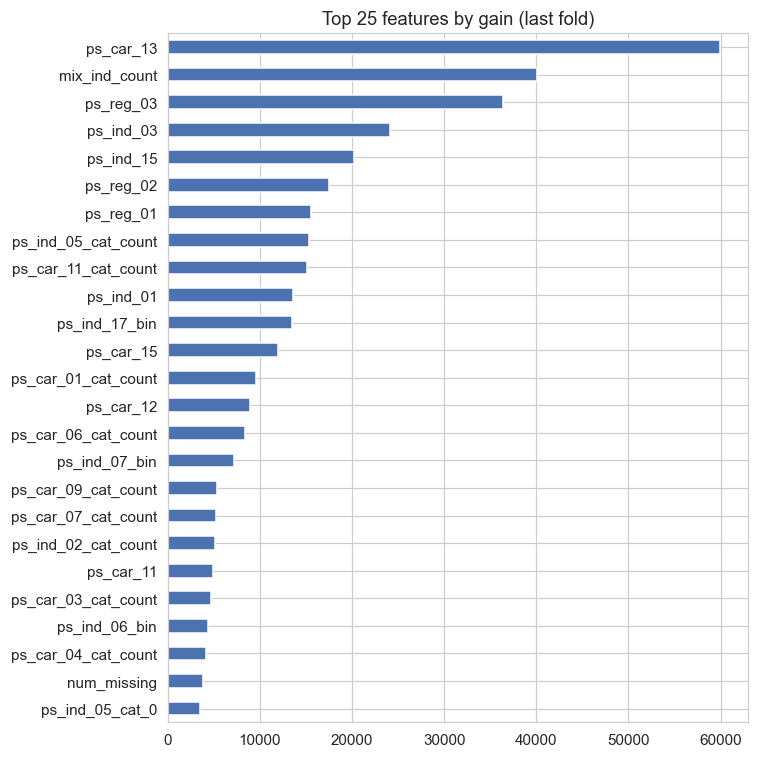

In [17]:
imp = pd.Series(model.feature_importance(importance_type="gain"),
                index=feat_names).sort_values(ascending=False)
ax = imp.head(25).iloc[::-1].plot(kind="barh", figsize=(7, 7), color="#4C72B0")
ax.set_title("Top 25 features by gain (last fold)")
plt.tight_layout(); plt.show()

## 7. Submission

In [18]:
submission = pd.DataFrame({"id": test_ids, "target": test_pred})
out_path = os.path.join(OUT_DIR, "submission.csv")
submission.to_csv(out_path, index=False)
print("Wrote", out_path, submission.shape)
submission.head()

Wrote ./submission.csv (892816, 2)


,id,target
0,0,0.027666
1,1,0.022522
2,2,0.023229
3,3,0.014288
4,4,0.037575


## 8. Summary

- **Imbalance handled by the metric, not resampling.** Gini / AUC are rank-based
  and robust to the 27:1 class ratio; Stratified K-Fold keeps the positive rate
  stable across folds. `scale_pos_weight` is available but off by default because
  it changes calibration, not ranking.
- **Feature engineering** added `num_missing`, `mix_ind`, count encodings, and
  one-hot categoricals, while dropping the non-informative `ps_calc_*` block and
  rare/redundant indicators — all assembled into a memory-efficient sparse matrix.
- **LightGBM + Bayesian optimization** tuned over the suggested ranges, with a
  low final learning rate, early stopping, and fold-averaged test probabilities.
- The out-of-fold Gini is an unbiased estimate of leaderboard performance; for
  reference, strong public solutions on this competition score ~0.29 Gini.